# **CNN-ABL — Modelo CNN sin preentrenamiento con Dataset Sintético**

Se selecciona el trial con menor `val_loss` del estudio Optuna (`OPT-CNN-ABL`) y se entrena mediante **5-fold cross-validation**, partiendo de **pesos aleatorios** (sin preentrenamiento en dataset sintético). Es el modelo de ablación para comparar contra el `CNN-FINAL` de Fase 2.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import gc
import csv
import json
import time
import random
import subprocess
import numpy as np
import pandas as pd
import psutil
import pynvml
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from datetime import datetime
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.metrics import classification_report, confusion_matrix, balanced_accuracy_score

C:\Users\Victoria\AppData\Local\Temp\ipykernel_10092\533497317.py:12: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml


In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.experimental.set_virtual_device_configuration(
        gpus[0],
        [tf.config.experimental.VirtualDeviceConfiguration(memory_limit=8192)]
    )
    print(f'GPU encontrada: {gpus[0].name} (límite: 8 GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite: 8 GB)


### **Configuración**

In [2]:
REPO_ROOT   = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH   = Path.home() / 'pfc' / 'Dataset ICBA Folds'
MODELS_PATH = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 3' / 'Modelo CNN'
MODELS_PATH.mkdir(parents=True, exist_ok=True)
print(f'Modelos: {MODELS_PATH}')

Modelos: C:\Users\Victoria\Desktop\TESIS_bioingenieria_JonquieresOrsi\Códigos\Modelos\Fase 3\Modelo CNN


In [3]:
ARQUITECTURA  = 'CNN-B'
DATASET       = 'ICBA'
OPTUNA_RUN_ID = 'OPT-CNN-ABL'
NUM_CLASSES   = 4
CLASSES       = ['Am', 'HTA', 'EAo', 'MCH']
ALL_FOLDS     = [1, 2, 3, 4, 5]

IMG_HEIGHT = 192
IMG_WIDTH  = 352
CHANNELS   = 1
BATCH_SIZE = 16
SEED       = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

LOSS_FUNCTION = 'sparse_categorical_crossentropy'
EPOCH_MAX     = 100
DENSE_UNITS   = 128   # fijo, igual que en OPT-CNN-ABL

ES_PATIENCE   = 8
ES_MIN_DELTA  = 0.0001
RLR_FACTOR    = 0.5
RLR_PATIENCE  = 5
RLR_MIN_DELTA = 0.0001
RLR_MIN_LR    = 1e-7

### **Selección del Top-1**

Se carga el CSV del estudio Optuna y se selecciona el trial completado con menor `val_loss`.

In [5]:
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top1        = df_complete.sort_values('value').head(1)

CONFIGS = []
for _, (trial_num, row) in enumerate(top1.iterrows()):
    CONFIGS.append({
        'run_id':          'CNN-ABL',
        'optuna_trial':    int(trial_num),
        'optuna_val_loss': float(row['value']),
        'num_blocks':      int(row['num_blocks']),
        'base_filters':    int(row['base_filters']),
        'dropout':         float(row['dropout']),
        'learning_rate':   float(row['learning_rate']),
    })

In [6]:
cfg = CONFIGS[0]
print(f"{cfg['run_id']}  (trial Optuna #{cfg['optuna_trial']} — val_loss: {cfg['optuna_val_loss']:.4f})")
print(f"  num_blocks    : {cfg['num_blocks']}")
print(f"  base_filters  : {cfg['base_filters']}")
print(f"  dense_units   : {DENSE_UNITS}  (fijo)")
print(f"  dropout       : {cfg['dropout']:.4f}")
print(f"  learning_rate : {cfg['learning_rate']:.2e}")

CNN-ABL  (trial Optuna #9 — val_loss: 0.8235)
  num_blocks    : 2
  base_filters  : 32
  dense_units   : 128  (fijo)
  dropout       : 0.3909
  learning_rate : 9.02e-04


### **Carga de Datos**

In [4]:
AUTOTUNE = tf.data.AUTOTUNE

def load_fold_images(fold_dirs, classes):
    X, y = [], []
    for fold_dir in fold_dirs:
        for label_idx, cls in enumerate(classes):
            cls_dir = Path(fold_dir) / cls
            if not cls_dir.exists():
                print(f'  Advertencia: {cls_dir} no existe')
                continue
            for f in sorted(cls_dir.iterdir()):
                if f.suffix.lower() in ('.jpg', '.jpeg'):
                    img = np.array(Image.open(f).convert('L'))
                    img = img[:, :, np.newaxis]   # H×W×1 grayscale
                    X.append(img)
                    y.append(label_idx)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

print('Cargando folds en memoria...')
X_folds, y_folds = {}, {}
for fold in ALL_FOLDS:
    fold_dir = DATA_PATH / 'train' / f'fold {fold}'
    X_folds[fold], y_folds[fold] = load_fold_images([fold_dir], CLASSES)
    counts = {cls: int((y_folds[fold] == i).sum()) for i, cls in enumerate(CLASSES)}
    print(f'  fold {fold}: {X_folds[fold].shape[0]} imgs  {counts}')

print('\nCargando test...')
X_test, y_test = load_fold_images([DATA_PATH / 'test'], CLASSES)
counts_test    = {cls: int((y_test == i).sum()) for i, cls in enumerate(CLASSES)}
print(f'  test : {X_test.shape[0]} imgs  {counts_test}')

total_train = sum(X_folds[f].shape[0] for f in ALL_FOLDS)
print(f'\nTotal train (5 folds): {total_train} | Test: {X_test.shape[0]}')

Cargando folds en memoria...
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\HTA no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\EAo no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 1\MCH no existe
  fold 1: 0 imgs  {'Am': 0, 'HTA': 0, 'EAo': 0, 'MCH': 0}
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\HTA no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\EAo no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 2\MCH no existe
  fold 2: 0 imgs  {'Am': 0, 'HTA': 0, 'EAo': 0, 'MCH': 0}
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 3\Am no existe
  Advertencia: C:\Users\Victoria\pfc\Dataset ICBA Folds\train\fold 3\HTA no existe
  Advertencia: C:\Users\Vict

### **Arquitectura**

CNN-B construida desde cero con pesos aleatorios. No se usa protocolo LP-FT — la red completa se entrena end-to-end con Adam y una única fase de entrenamiento.

In [8]:
def build_cnn_b(num_blocks, base_filters, dense_units, dropout,
                input_shape=(192, 352, 1), num_classes=4):
    inputs = tf.keras.Input(shape=input_shape)
    x = inputs

    for i in range(num_blocks):
        filters = base_filters * (2 ** i)
        drop_i  = min(dropout + i * 0.05, 0.4)

        residual = x

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.ReLU()(x)

        x = layers.Conv2D(filters, (3, 3), padding='same')(x)
        x = layers.BatchNormalization()(x)

        if residual.shape[-1] != filters:
            residual = layers.Conv2D(filters, (1, 1), padding='same')(residual)
            residual = layers.BatchNormalization()(residual)

        x = layers.Add()([x, residual])
        x = layers.ReLU()(x)

        x = layers.MaxPooling2D((2, 2))(x)
        x = layers.Dropout(drop_i)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    return tf.keras.Model(inputs=inputs, outputs=x, name='CNN_B_Ablation')

### **Monitoreo de Recursos y Logging**

In [9]:
def _append_csv(filepath, row):
    filepath  = Path(filepath)
    write_hdr = not filepath.exists()
    with open(filepath, 'a', newline='', encoding='utf-8') as f:
        w = csv.DictWriter(f, fieldnames=row.keys())
        if write_hdr:
            w.writeheader()
        w.writerow(row)

try:
    pynvml.nvmlInit()
    _GPU_HANDLE    = pynvml.nvmlDeviceGetHandleByIndex(0)
    _GPU_AVAILABLE = True
except Exception:
    _GPU_AVAILABLE = False

class ResourceMonitor(tf.keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.ram_max  = 0.0
        self.vram_max = 0.0
        self._pid     = os.getpid()

    def on_epoch_end(self, epoch, logs=None):
        self.ram_max = max(self.ram_max, psutil.Process().memory_info().rss / 1e9)
        if _GPU_AVAILABLE:
            for proc in pynvml.nvmlDeviceGetComputeRunningProcesses(_GPU_HANDLE):
                if proc.pid == self._pid:
                    self.vram_max = max(self.vram_max, proc.usedGpuMemory / 1e9)
                    break


def log_training(cfg, val_fold, train_folds, history, monitor, t_start, t_end,
                 model_path, hist_path):
    best_ep = int(np.argmin(history.history['val_loss']))
    row = {
        'run_id':          cfg['run_id'],
        'val_fold':        val_fold,
        'train_folds':     ','.join(str(f) for f in train_folds),
        'fecha':           datetime.now().strftime('%d/%m/%Y'),
        'arquitectura':    ARQUITECTURA,
        'base_model_id':   'random_init',
        'dataset':         DATASET,
        'img_width':       IMG_WIDTH,
        'img_height':      IMG_HEIGHT,
        'channels':        CHANNELS,
        'batch_size':      BATCH_SIZE,
        'seed':            SEED,
        'optuna_run_id':   f"{OPTUNA_RUN_ID}_trial{cfg['optuna_trial']}",
        'num_blocks':      cfg['num_blocks'],
        'base_filters':    cfg['base_filters'],
        'dense_units':     DENSE_UNITS,
        'dropout':         round(cfg['dropout'], 4),
        'learning_rate':   cfg['learning_rate'],
        'loss_function':   LOSS_FUNCTION,
        'epochs_trained':  len(history.history['val_loss']),
        'best_epoch':      best_ep + 1,
        'es_patience':     ES_PATIENCE,
        'es_min_delta':    ES_MIN_DELTA,
        'rlr_factor':      RLR_FACTOR,
        'rlr_patience':    RLR_PATIENCE,
        'rlr_min_delta':   RLR_MIN_DELTA,
        'rlr_min_lr':      RLR_MIN_LR,
        'epoch_max':       EPOCH_MAX,
        't_start':         datetime.fromtimestamp(t_start).strftime('%d/%m - %H:%M:%S'),
        't_end':           datetime.fromtimestamp(t_end).strftime('%d/%m - %H:%M:%S'),
        't_min':           round((t_end - t_start) / 60, 2),
        'ram_max_gb':      round(monitor.ram_max, 2),
        'vram_max_gb':     round(monitor.vram_max, 2),
        'model_path':      str(model_path.relative_to(REPO_ROOT)),
        'history_path':    str(hist_path.relative_to(REPO_ROOT)),
    }
    _append_csv(MODELS_PATH / 'CNN_ABL_training.csv', row)
    print(f"  CNN_ABL_training.csv actualizado — fold {val_fold}")

### **Entrenamiento con Cross-Validation**

Se entrena el top-1 con **5-fold cross-validation**. Por cada fold se guarda el modelo (`.keras`) y el historial de entrenamiento (`.json`).

In [11]:
HISTORIES_CV = {}

for cfg in CONFIGS:
    run_id = cfg['run_id']
    print(f'\n{"="*65}')
    print(f'{run_id}  (trial #{cfg["optuna_trial"]} — num_blocks={cfg["num_blocks"]}, base_filters={cfg["base_filters"]}, dropout={cfg["dropout"]:.3f}, lr={cfg["learning_rate"]:.2e})')
    print(f'{"="*65}')

    HISTORIES_CV[run_id] = []
    val_losses = []
    val_accs   = []

    for val_fold in ALL_FOLDS:
        train_folds_cv = [f for f in ALL_FOLDS if f != val_fold]
        print(f'\n  Fold val={val_fold}  |  train={train_folds_cv}')

        tf.keras.backend.clear_session()
        gc.collect()
        random.seed(SEED)
        np.random.seed(SEED)
        tf.random.set_seed(SEED)

        X_train_cv = np.concatenate([X_folds[f] for f in train_folds_cv])
        y_train_cv = np.concatenate([y_folds[f] for f in train_folds_cv])
        X_val_cv   = X_folds[val_fold]
        y_val_cv   = y_folds[val_fold]

        np.random.seed(SEED)
        idx        = np.random.permutation(len(X_train_cv))
        X_train_cv = X_train_cv[idx]
        y_train_cv = y_train_cv[idx]

        train_ds = (
            tf.data.Dataset.from_tensor_slices((X_train_cv, y_train_cv))
            .shuffle(len(X_train_cv), seed=SEED, reshuffle_each_iteration=True)
            .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE)
        )
        val_ds = (
            tf.data.Dataset.from_tensor_slices((X_val_cv, y_val_cv))
            .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(AUTOTUNE)
        )

        model            = build_cnn_b(
            num_blocks   = cfg['num_blocks'],
            base_filters = cfg['base_filters'],
            dense_units  = DENSE_UNITS,
            dropout      = cfg['dropout'],
            input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
            num_classes  = NUM_CLASSES,
        )
        resource_monitor = ResourceMonitor()
        checkpoint_path  = MODELS_PATH / f'CNN-ABL-{val_fold}.keras'
        hist_path        = MODELS_PATH / f'CNN-ABL-{val_fold}_history.json'

        model.compile(
            optimizer = tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']),
            loss      = LOSS_FUNCTION,
            metrics   = ['accuracy'],
        )
        t_start = time.time()
        history = model.fit(
            train_ds, validation_data=val_ds, epochs=EPOCH_MAX,
            callbacks=[
                EarlyStopping(monitor='val_loss', patience=ES_PATIENCE, min_delta=ES_MIN_DELTA,
                              restore_best_weights=True),
                ReduceLROnPlateau(monitor='val_loss', factor=RLR_FACTOR, patience=RLR_PATIENCE,
                                  min_delta=RLR_MIN_DELTA, min_lr=RLR_MIN_LR),
                ModelCheckpoint(filepath=checkpoint_path, monitor='val_loss', save_best_only=True, verbose=0),
                resource_monitor,
            ],
            verbose=1,
        )
        t_end = time.time()
        with open(hist_path, 'w') as f:
            json.dump(history.history, f)

        HISTORIES_CV[run_id].append(history.history)
        log_training(cfg, val_fold, train_folds_cv, history, resource_monitor,
                     t_start, t_end, checkpoint_path, hist_path)

        best_ep   = int(np.argmin(history.history['val_loss']))
        best_loss = round(history.history['val_loss'][best_ep], 4)
        best_acc  = round(history.history['val_accuracy'][best_ep], 4)
        epochs_t  = len(history.history['val_loss'])
        val_losses.append(best_loss)
        val_accs.append(best_acc)
        print(f'    val_loss={best_loss:.4f} | val_acc={best_acc:.4f} | epochs={epochs_t} | {round((t_end - t_start)/60, 1)} min')

        del model, train_ds, val_ds, history, X_train_cv, y_train_cv, resource_monitor
        gc.collect()
        tf.keras.backend.clear_session()
        gc.collect()

    mean_loss = float(np.mean(val_losses))
    mean_acc  = float(np.mean(val_accs))
    print(f'\n  {run_id} CV (val): val_loss={mean_loss:.4f} | val_acc={mean_acc:.4f}')

print('\nCross-validation completada.')


CNN-ABL  (trial #9 — num_blocks=2, base_filters=32, dropout=0.391, lr=9.02e-04)

  Fold val=1  |  train=[2, 3, 4, 5]
Epoch 1/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 43s 227ms/step - accuracy: 0.2945 - loss: 1.5115 - val_accuracy: 0.2703 - val_loss: 1.3916 - learning_rate: 9.0180e-04
Epoch 2/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - accuracy: 0.2945 - loss: 1.3950 - val_accuracy: 0.2703 - val_loss: 1.3991 - learning_rate: 9.0180e-04
Epoch 3/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.3607 - loss: 1.3437 - val_accuracy: 0.2703 - val_loss: 1.4001 - learning_rate: 9.0180e-04
Epoch 4/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.3995 - loss: 1.3069 - val_accuracy: 0.2703 - val_loss: 1.4040 - learning_rate: 9.0180e-04
Epoch 5/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 100ms/step - accuracy: 0.4566 - loss: 1.2567 - val_accuracy: 0.2613 - val_loss: 1.4189 - learning_rate: 9.0180e-04
Epoch 6/100
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 101ms/step - accuracy: 0.4452 - loss: 1.2139 - val_acc

### **Resultados**

#### **Reconstrucción de contexto tras reinicio de kernel**

Correr la siguiente celda **solo si el kernel fue reiniciado** después del entrenamiento. Antes de correrla, ejecutar todas las celdas anteriores al bloque de entrenamiento.

In [5]:
# ── RECONSTRUCCIÓN DE CONTEXTO ────────────────────────────────────────────────
df_opt      = pd.read_csv(MODELS_PATH / f'{OPTUNA_RUN_ID}.csv', index_col='trial')
df_complete = df_opt[df_opt['state'] == 'COMPLETE'].copy()
top1        = df_complete.sort_values('value').head(1)

CONFIGS = []
for _, (trial_num, row) in enumerate(top1.iterrows()):
    CONFIGS.append({
        'run_id':          'CNN-ABL',
        'optuna_trial':    int(trial_num),
        'optuna_val_loss': float(row['value']),
        'num_blocks':      int(row['num_blocks']),
        'base_filters':    int(row['base_filters']),
        'dropout':         float(row['dropout']),
        'learning_rate':   float(row['learning_rate']),
    })

HISTORIES_CV = {}
for cfg in CONFIGS:
    run_id = cfg['run_id']
    HISTORIES_CV[run_id] = []
    for val_fold in ALL_FOLDS:
        with open(MODELS_PATH / f'CNN-ABL-{val_fold}_history.json') as f:
            HISTORIES_CV[run_id].append(json.load(f))

print('Contexto reconstruido.')
cfg         = CONFIGS[0]
best_losses = [min(h['val_loss']) for h in HISTORIES_CV[cfg['run_id']]]
print(f"  {cfg['run_id']}: val_loss_mean={float(np.mean(best_losses)):.4f}")

Contexto reconstruido.
  CNN-ABL: val_loss_mean=1.2797


#### **Curvas de Entrenamiento**

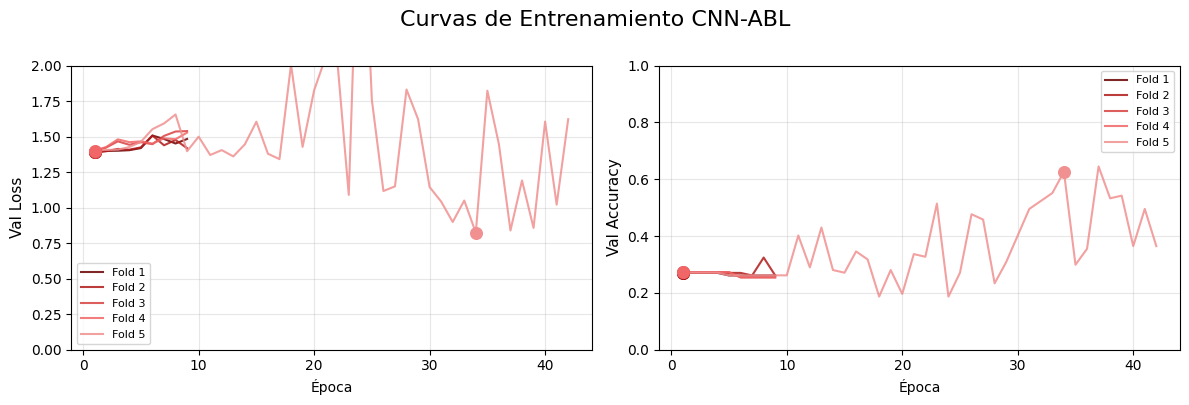

In [10]:
FOLD_COLORS = ['#6B0000', '#B11919', '#D94040', '#F16666', '#F09090']


cfg    = CONFIGS[0]
run_id = cfg['run_id']
hs     = HISTORIES_CV[run_id]

vl_all   = [h['val_loss']     for h in hs]
va_all   = [h['val_accuracy'] for h in hs]
best_eps = [int(np.argmin(h['val_loss'])) + 1 for h in hs]

fig, (ax0, ax1) = plt.subplots(1, 2, figsize=(12, 4))

for i, (fold, vl, va, be) in enumerate(zip(ALL_FOLDS, vl_all, va_all, best_eps)):
    color = FOLD_COLORS[i]
    eps   = np.arange(1, len(vl) + 1)
    ax0.plot(eps, vl, color=color, linewidth=1.5, label=f'Fold {fold}', alpha=0.85)
    ax0.scatter([be], [vl[be - 1]], color=color, s=70, zorder=5)
    ax1.plot(eps, va, color=color, linewidth=1.5, label=f'Fold {fold}', alpha=0.85)
    ax1.scatter([be], [va[be - 1]], color=color, s=70, zorder=5)

for ax in [ax0, ax1]:
    ax.set_xlabel('Época')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

ax0.set_ylabel('Val Loss',     fontsize=11)
ax0.set_ylim(0, 2)
ax1.set_ylabel('Val Accuracy', fontsize=11)
ax1.set_ylim(0, 1)

plt.suptitle(f'Curvas de Entrenamiento {run_id}', fontsize=16, y=1)
plt.tight_layout()
plt.show()

#### **Evaluación en Test**

In [15]:
def log_results(run_id, val_fold, train_folds, history, y_true, y_pred, test_loss, test_acc):
    best_ep = int(np.argmin(history['val_loss']))
    report  = classification_report(y_true, y_pred, target_names=CLASSES, output_dict=True, zero_division=0)
    row = {
        'run_id':        run_id,
        'val_fold':      val_fold,
        'train_folds':   ','.join(str(f) for f in train_folds),
        'best_epoch':    best_ep + 1,
        'best_val_loss': round(history['val_loss'][best_ep], 4),
        'best_val_acc':  round(history['val_accuracy'][best_ep], 4),
        'test_loss':     round(test_loss, 4),
        'test_acc':      round(test_acc, 4),
        'balanced_acc':  round(balanced_accuracy_score(y_true, y_pred), 4),
        'macro_f1':      round(report['macro avg']['f1-score'], 4),
        'weighted_f1':   round(report['weighted avg']['f1-score'], 4),
        **{f'precision_{cls}': round(report[cls]['precision'], 4) for cls in CLASSES},
        **{f'recall_{cls}':    round(report[cls]['recall'],    4) for cls in CLASSES},
        **{f'f1_{cls}':        round(report[cls]['f1-score'],  4) for cls in CLASSES},
        **{f'support_{cls}':   int(report[cls]['support'])        for cls in CLASSES},
    }
    _append_csv(MODELS_PATH / 'CNN_ABL_results.csv', row)
    return row


# Limpiar CSV si existe (evita duplicados al re-ejecutar la celda)
results_csv = MODELS_PATH / 'CNN_ABL_results.csv'
if results_csv.exists():
    results_csv.unlink()

cfg       = CONFIGS[0]
run_id    = cfg['run_id']
fold_rows = []

print(f'Evaluando 5 modelos CNN-ABL en test...\n')
for val_fold in ALL_FOLDS:
    train_folds_cv = [f for f in ALL_FOLDS if f != val_fold]

    with open(MODELS_PATH / f'CNN-ABL-{val_fold}_history.json') as f:
        history = json.load(f)

    test_ds = (
        tf.data.Dataset.from_tensor_slices((X_test, y_test))
        .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    model               = tf.keras.models.load_model(MODELS_PATH / f'CNN-ABL-{val_fold}.keras')
    y_pred              = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    test_loss, test_acc = model.evaluate(test_ds, verbose=0)
    del model
    tf.keras.backend.clear_session()
    gc.collect()

    row = log_results(run_id, val_fold, train_folds_cv, history, y_test, y_pred, test_loss, test_acc)
    fold_rows.append(row)
    print(f'  CNN-ABL-{val_fold}: balanced_acc={row["balanced_acc"]:.4f} | macro_f1={row["macro_f1"]:.4f}')

mean_bacc = float(np.mean([r['balanced_acc'] for r in fold_rows]))
mean_f1   = float(np.mean([r['macro_f1']     for r in fold_rows]))
print(f'\n  mean : balanced_acc={mean_bacc:.4f} | macro_f1={mean_f1:.4f}')
print('\nCNN_ABL_results.csv guardado.')

Evaluando 5 modelos CNN-ABL en test...

  CNN-ABL-1: balanced_acc=0.2500 | macro_f1=0.1063
  CNN-ABL-2: balanced_acc=0.2500 | macro_f1=0.1063
  CNN-ABL-3: balanced_acc=0.2500 | macro_f1=0.1063
  CNN-ABL-4: balanced_acc=0.2500 | macro_f1=0.1063
  CNN-ABL-5: balanced_acc=0.5511 | macro_f1=0.5177

  mean : balanced_acc=0.3102 | macro_f1=0.1886

CNN_ABL_results.csv guardado.


#### **Tabla de Resultados**

In [16]:
df_res = pd.read_csv(MODELS_PATH / 'CNN_ABL_results.csv')

df_res['macro_precision'] = df_res[[f'precision_{cls}' for cls in CLASSES]].mean(axis=1).round(4)
df_res['macro_recall']    = df_res[[f'recall_{cls}'    for cls in CLASSES]].mean(axis=1).round(4)

col_map = {
    'balanced_acc':    'Balanced Accuracy',
    'test_acc':        'Accuracy',
    'macro_precision': 'Precision',
    'macro_recall':    'Recall',
    'macro_f1':        'F1-macro',
    'f1_Am':           'F1-Am',
    'f1_HTA':          'F1-HTA',
    'f1_EAo':          'F1-EAo',
    'f1_MCH':          'F1-MCH',
    'val_fold':        'Fold',
}

df_table = df_res[list(col_map.keys())].rename(columns=col_map).copy()
df_table['Fold'] = df_table['Fold'].astype(str)

mean_vals        = df_table.drop(columns='Fold').mean().round(4)
mean_row         = mean_vals.to_frame().T
mean_row['Fold'] = 'Media'
df_table         = pd.concat([df_table, mean_row], ignore_index=True)

metric_cols = [c for c in df_table.columns if c != 'Fold']
df_table    = df_table[metric_cols + ['Fold']]

fmt = {c: '{:.4f}' for c in metric_cols}
display(df_table.style.format(fmt, na_rep='-').hide(axis='index'))

Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH,Fold
0.2500,0.2701,0.0675,0.2500,0.1063,0.4253,0.0000,0.0000,0.0000,1
0.2500,0.2701,0.0675,0.2500,0.1063,0.4253,0.0000,0.0000,0.0000,2
0.2500,0.2701,0.0675,0.2500,0.1063,0.4253,0.0000,0.0000,0.0000,3
0.2500,0.2701,0.0675,0.2500,0.1063,0.4253,0.0000,0.0000,0.0000,4
0.5511,0.5328,0.5522,0.5511,0.5177,0.6222,0.4828,0.3860,0.5797,5
0.3102,0.3226,0.1644,0.3102,0.1886,0.4647,0.0966,0.0772,0.1159,Media


---

# **CNN-ABL-FINAL — Modelo CNN Ablación**

Se reentrena la configuración ganadora de Optuna sobre la totalidad de los datos de entrenamiento (5 folds). El número de épocas se fija como la mediana de los `best_epoch` obtenidos en el cross-validation. No se usan callbacks de Early Stopping ni ReduceLROnPlateau porque no hay val_loss para monitorear.

Al finalizar se evalúa una única vez sobre el conjunto de test.

In [17]:
cfg    = CONFIGS[0]
run_id = 'CNN-ABL-FINAL'

best_epochs = [int(np.argmin(h['val_loss'])) + 1 for h in HISTORIES_CV[cfg['run_id']]]
median_ep   = int(np.median(best_epochs))

print(f'best_epoch por fold : {best_epochs}')
print(f'Mediana             : {median_ep} épocas')

best_epoch por fold : [1, 1, 1, 1, 34]
Mediana             : 1 épocas


In [18]:
tf.keras.backend.clear_session()
gc.collect()
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

X_all = np.concatenate([X_folds[f] for f in ALL_FOLDS])
y_all = np.concatenate([y_folds[f] for f in ALL_FOLDS])

np.random.seed(SEED)
idx   = np.random.permutation(len(X_all))
X_all = X_all[idx]
y_all = y_all[idx]

train_ds_final = (
    tf.data.Dataset.from_tensor_slices((X_all, y_all))
    .shuffle(len(X_all), seed=SEED, reshuffle_each_iteration=True)
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

model_final = build_cnn_b(
    num_blocks   = cfg['num_blocks'],
    base_filters = cfg['base_filters'],
    dense_units  = DENSE_UNITS,
    dropout      = cfg['dropout'],
    input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    num_classes  = NUM_CLASSES,
)
model_final.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']),
    loss      = LOSS_FUNCTION,
    metrics   = ['accuracy'],
)
t_start          = time.time()
history_final    = model_final.fit(
    train_ds_final, epochs=median_ep, verbose=1,
)
t_end = time.time()

model_final.save(MODELS_PATH / 'CNN-ABL-FINAL.keras')
with open(MODELS_PATH / 'CNN-ABL-FINAL_history.json', 'w') as f:
    json.dump(history_final.history, f)

print(f'\nModelo final guardado : CNN-ABL-FINAL.keras')
print(f'Tiempo total          : {(t_end - t_start)/60:.1f} min')

35/35 ━━━━━━━━━━━━━━━━━━━━ 6s 101ms/step - accuracy: 0.3097 - loss: 1.4830

Modelo final guardado : CNN-ABL-FINAL.keras
Tiempo total          : 0.1 min


#### **Resultados**

In [19]:
test_ds_final = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
_m_f     = tf.keras.models.load_model(MODELS_PATH / 'CNN-ABL-FINAL.keras')
probs_f  = _m_f.predict(test_ds_final, verbose=0)
y_pred_f = np.argmax(probs_f, axis=1)
del _m_f; gc.collect(); tf.keras.backend.clear_session(); gc.collect()

report_f = classification_report(y_test, y_pred_f, target_names=CLASSES, output_dict=True, zero_division=0)
ba_f     = balanced_accuracy_score(y_test, y_pred_f)
row_f    = {
    'Modelo':            'CNN-ABL-FINAL',
    'Balanced Accuracy': round(ba_f, 4),
    'Accuracy':          round((y_pred_f == y_test).mean(), 4),
    'Precision':         round(float(np.mean([report_f[c]['precision'] for c in CLASSES])), 4),
    'Recall':            round(float(np.mean([report_f[c]['recall']    for c in CLASSES])), 4),
    'F1-macro':          round(report_f['macro avg']['f1-score'], 4),
    'F1-Am':             round(report_f['Am']['f1-score'],  4),
    'F1-HTA':            round(report_f['HTA']['f1-score'], 4),
    'F1-EAo':            round(report_f['EAo']['f1-score'], 4),
    'F1-MCH':            round(report_f['MCH']['f1-score'], 4),
}
_mcols_f = [c for c in row_f if c != 'Modelo']

Modelo,Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
CNN-ABL-FINAL,0.2500,0.1898,0.0474,0.2500,0.0798,0.0000,0.0000,0.0000,0.3190


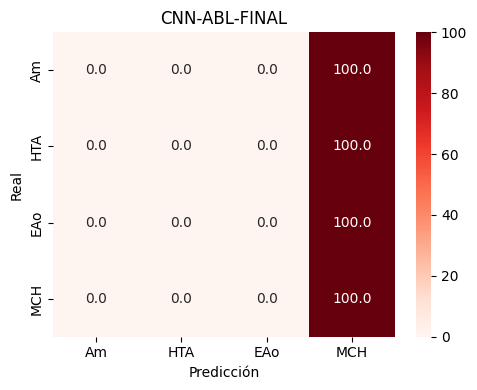

In [20]:
# Métricas
display(pd.DataFrame([row_f]).style.format({c: '{:.4f}' for c in _mcols_f}).hide(axis='index'))

# Matriz de confusión
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_f, normalize='true') * 100,
            annot=True, fmt='.1f', cmap='Reds',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, vmin=0, vmax=100)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('CNN-ABL-FINAL')
plt.tight_layout()
plt.show()

---

# **CNN-ABL-ALT — Evaluación Alternativa**

El modelo final entrenado siguiendo el protocolo establecido corrió solo 1 época. Dado que el resultado catastrófico podría atribuirse justamente a la cantidad insuficiente de épocas de entrenamiento más que a las limitaciones del modelo en sí, se realizó una evaluación adicional entrenando por 8 épocas (media de `best_epoch` en CV) para descartar esta hipótesis.

In [10]:
mean_ep = 8  # media de best_epoch en CV

tf.keras.backend.clear_session()
gc.collect()
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

X_all = np.concatenate([X_folds[f] for f in ALL_FOLDS])
y_all = np.concatenate([y_folds[f] for f in ALL_FOLDS])

np.random.seed(SEED)
idx   = np.random.permutation(len(X_all))
X_all = X_all[idx]
y_all = y_all[idx]

train_ds_alt = (
    tf.data.Dataset.from_tensor_slices((X_all, y_all))
    .shuffle(len(X_all), seed=SEED, reshuffle_each_iteration=True)
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

cfg       = CONFIGS[0]
model_alt = build_cnn_b(
    num_blocks   = cfg['num_blocks'],
    base_filters = cfg['base_filters'],
    dense_units  = DENSE_UNITS,
    dropout      = cfg['dropout'],
    input_shape  = (IMG_HEIGHT, IMG_WIDTH, CHANNELS),
    num_classes  = NUM_CLASSES,
)
model_alt.compile(
    optimizer = tf.keras.optimizers.Adam(learning_rate=cfg['learning_rate']),
    loss      = LOSS_FUNCTION,
    metrics   = ['accuracy'],
)
t_start     = time.time()
history_alt = model_alt.fit(train_ds_alt, epochs=mean_ep, verbose=1)
t_end       = time.time()

model_alt.save(MODELS_PATH / 'CNN-ABL-ALT.keras')
with open(MODELS_PATH / 'CNN-ABL-ALT_history.json', 'w') as f:
    json.dump(history_alt.history, f)

print(f'\nModelo alternativo guardado : CNN-ABL-ALT.keras')
print(f'Tiempo total                : {(t_end - t_start)/60:.1f} min')

Epoch 1/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 15s 97ms/step - accuracy: 0.3097 - loss: 1.4830
Epoch 2/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.3570 - loss: 1.3492
Epoch 3/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.3661 - loss: 1.3311
Epoch 4/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.3825 - loss: 1.2956
Epoch 5/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.4299 - loss: 1.2349
Epoch 6/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.4772 - loss: 1.1908
Epoch 7/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.5027 - loss: 1.1339
Epoch 8/8
35/35 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.4699 - loss: 1.0914

Modelo alternativo guardado : CNN-ABL-ALT.keras
Tiempo total                : 0.6 min


#### **Resultados**

Modelo,Balanced Accuracy,Accuracy,Precision,Recall,F1-macro,F1-Am,F1-HTA,F1-EAo,F1-MCH
CNN-ABL-ALT,0.2500,0.2774,0.0693,0.2500,0.1086,0.0000,0.0000,0.4343,0.0000


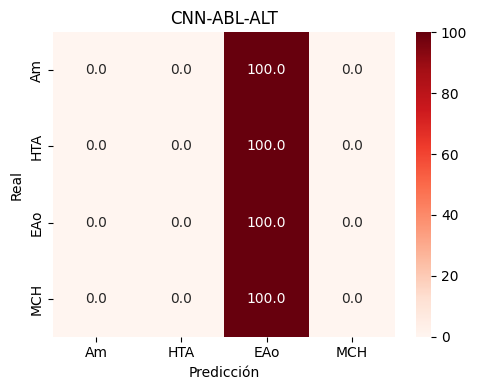

In [11]:
test_ds_alt = (
    tf.data.Dataset.from_tensor_slices((X_test, y_test))
    .map(lambda x, y: (tf.cast(x, tf.float32) / 255.0, y), num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)
_m_a     = tf.keras.models.load_model(MODELS_PATH / 'CNN-ABL-ALT.keras')
probs_a  = _m_a.predict(test_ds_alt, verbose=0)
y_pred_a = np.argmax(probs_a, axis=1)
del _m_a; gc.collect(); tf.keras.backend.clear_session(); gc.collect()

report_a = classification_report(y_test, y_pred_a, target_names=CLASSES, output_dict=True, zero_division=0)
ba_a     = balanced_accuracy_score(y_test, y_pred_a)
row_a    = {
    'Modelo':            'CNN-ABL-ALT',
    'Balanced Accuracy': round(ba_a, 4),
    'Accuracy':          round((y_pred_a == y_test).mean(), 4),
    'Precision':         round(float(np.mean([report_a[c]['precision'] for c in CLASSES])), 4),
    'Recall':            round(float(np.mean([report_a[c]['recall']    for c in CLASSES])), 4),
    'F1-macro':          round(report_a['macro avg']['f1-score'], 4),
    'F1-Am':             round(report_a['Am']['f1-score'],  4),
    'F1-HTA':            round(report_a['HTA']['f1-score'], 4),
    'F1-EAo':            round(report_a['EAo']['f1-score'], 4),
    'F1-MCH':            round(report_a['MCH']['f1-score'], 4),
}
_mcols_a = [c for c in row_a if c != 'Modelo']
display(pd.DataFrame([row_a]).style.format({c: '{:.4f}' for c in _mcols_a}).hide(axis='index'))

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_a, normalize='true') * 100,
            annot=True, fmt='.1f', cmap='Reds',
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax, vmin=0, vmax=100)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('CNN-ABL-ALT')
plt.tight_layout(); plt.show()

La ausencia de mejora significativa confirma que el rendimiento deficiente no es consecuencia del número de épocas, sino de la falta de preentrenamiento. Con 8 épocas el modelo colapsa igualmente a predecir una única clase (EAo, la más frecuente del conjunto de entrenamiento), comportamiento consistente con un modelo que no logra extraer features discriminativas con el volumen de datos disponible. El preentrenamiento sobre el dataset sintético resulta, por lo tanto, indispensable para que la red alcance una inicialización suficientemente informativa como para generalizar con datos reales limitados.